#Session 13


### Question 1.1 — What is the nullspace of X, and why can it be ignored when finding the optimal weights for a linear parameter model?

The nullspace contains weight vectors that do not change the model's predictions. If X is our input matrix and v belongs to its nullspace, then:

$$
Xv = 0
$$

Adding v to a weight vector w does not change the predictions:

$$
X(w+v)=Xw+Xv=Xw
$$

This means the nullspace does not help the model predict the target. With L2 regularization, unnecessary nullspace components increase the penalty without improving predictions.

**Interpretation:** The model should focus on weights that affect its output; any weight component that does nothing is unnecessary.



### Question 1.2 — Why can optimal weights be represented as a linear combination of the training data points?

For the regularized linear models discussed in class, the representer theorem tells us that an optimal weight vector can be expressed using training examples:

$$
w^*=\sum_{i=1}^{n}\alpha_i x_i
$$

Here, each training example contributes to the final weights through a coefficient.

For support vector classifiers, the weights in feature space can be expressed as:

$$
w=\sum_{i=1}^{n}\alpha_i y_i\phi(x_i)
$$

Only training examples with nonzero coefficients contribute to this expression. These examples are called support vectors.

**Interpretation:** The model can construct its decision boundary using the training examples. This also helps explain why the kernel trick works.



### Question 1.3 — Use a generative model to create a simple SVC classifier and an SVC classifier with an RBF kernel

I implemented two functions to create support vector classifiers. The first uses a linear kernel, while the second uses an RBF kernel.

I chose a linear kernel for the simple classifier to make the comparison meaningful. The RBF kernel is already the default in scikit-learn.

A linear classifier learns a straight decision boundary. An RBF classifier can learn a curved boundary, which may be more useful when the classes overlap in a nonlinear way.


In [12]:
import numpy as np
from sklearn.datasets import make_classification, make_moons
from sklearn.svm import SVC

# Creating a simple linear support vector classifier
def create_simple_svc():
    return SVC(kernel="linear", probability=True, random_state=42)

# Creating a support vector classifier with an RBF kernel
def create_rbf_svc(c_value=1.0, gamma_value="scale"):
    return SVC(kernel="rbf", C=c_value, gamma=gamma_value)

# Generating data with two informative features
X_linear, y_linear = make_classification(n_samples=100, n_features=2, n_informative=2, n_redundant=0, random_state=42)

# Training the simple classifier
simple_svc = create_simple_svc()
simple_svc.fit(X_linear, y_linear)

# Predicting the class of a new observation
new_point = np.array([[-0.5, 0.5]])
print("Linear prediction:", simple_svc.predict(new_point)[0])
print("Linear probabilities:", simple_svc.predict_proba(new_point)[0])

# Generating nonlinear, moon-shaped data
X_moons, y_moons = make_moons(n_samples=100, noise=0.1, random_state=42)

# Training the RBF classifier
rbf_svc = create_rbf_svc(c_value=1.0, gamma_value="scale")
rbf_svc.fit(X_moons, y_moons)

# Predicting the class of a new observation
print("RBF prediction:", rbf_svc.predict(np.array([[1.0, 0.5]]))[0])

Linear prediction: 0
Linear probabilities: [0.92314902 0.07685098]
RBF prediction: 0



### Question 2.1 — Find the appropriate parameterizations for the linear and quadratic kernels

**Linear kernel**

$$
K(x,z)=x^Tz
$$

The feature transformation is:

$$
\phi(x)=x
$$

The linear kernel does not transform the features into a higher-dimensional space.

**Homogeneous quadratic kernel**

$$
K(x,z)=(x^Tz)^2
$$

For two features, the transformation is:

$$
\phi(x)=(x_1^2,\sqrt{2}x_1x_2,x_2^2)
$$

**Inhomogeneous quadratic kernel**

For a constant of 1:

$$
K(x,z)=(x^Tz+1)^2
$$

Its feature transformation is:

$$
\phi(x)=(x_1^2,\sqrt{2}x_1x_2,x_2^2,\sqrt{2}x_1,\sqrt{2}x_2,1)
$$

**Interpretation:** A quadratic kernel captures interactions between features that a linear model cannot represent directly. The kernel trick allows us to use these relationships without explicitly constructing every transformed feature.



### Question 2.2 — Implement a kernel SVM using scikit-learn

I used the Banknote Authentication dataset from the class example. The dataset contains four numerical measurements and a class label.

I separated the measurements from the target, then divided the observations into training and testing sets.

I reserved 20% of the observations for testing and used a fixed random state of 42. This allows me to reproduce the original comparison.

**Justification:** Testing the model on unseen observations helps determine how well it generalizes beyond the training data.


In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

# Loading the original banknote dataset
banknote_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

column_names = ["variance", "skewness", "curtosis", "entropy", "class"]
bankdata = pd.read_csv(banknote_url, header=None, names=column_names)

# Separating the features from the target
X_bank = bankdata.drop(columns="class")
y_bank = bankdata["class"]

# Splitting the data into training and testing sets
X_bank_train, X_bank_test, y_bank_train, y_bank_test = train_test_split(X_bank, y_bank, test_size=0.20, random_state=42)

# Inspecting the dataset
print("Dataset shape:", bankdata.shape)
display(bankdata.head())

Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



### Question 2.3 — Compare linear, quadratic, and RBF kernels on the banknote dataset

I compared three support vector classifiers using the same training and testing observations.

The linear kernel learns a straight decision boundary. The quadratic kernel adds second-order relationships, while the RBF kernel allows more flexible nonlinear boundaries.

I kept the original experiment settings to preserve the comparison from my submitted work.

**Justification:** Since all three classifiers use the same data split, I can compare their test accuracy directly. This helps me evaluate whether a more flexible kernel improves classification.


In [14]:
# Defining the three support vector classifiers
bank_models = {
    "Linear": SVC(kernel="linear"),
    "Quadratic": SVC(kernel="poly", degree=2, coef0=0),
    "RBF": SVC(kernel="rbf")
}

bank_scores = {}

# Training and evaluating each classifier
for name, model in bank_models.items():
    model.fit(X_bank_train, y_bank_train)

    predictions = model.predict(X_bank_test)
    bank_scores[name] = accuracy_score(y_bank_test, predictions)

    print(f"\n--- {name} kernel ---")
    print(classification_report(y_bank_test, predictions))

# Identifying the best-performing kernel
best_bank_kernel = max(bank_scores, key=bank_scores.get)

print(f"Best kernel: {best_bank_kernel}")
print(f"Best accuracy: {bank_scores[best_bank_kernel]:.2%}")


--- Linear kernel ---
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       148
           1       0.98      0.98      0.98       127

    accuracy                           0.99       275
   macro avg       0.99      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275


--- Quadratic kernel ---
              precision    recall  f1-score   support

           0       1.00      0.95      0.98       148
           1       0.95      1.00      0.97       127

    accuracy                           0.97       275
   macro avg       0.97      0.98      0.97       275
weighted avg       0.98      0.97      0.97       275


--- RBF kernel ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       148
           1       1.00      1.00      1.00       127

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weigh


### Interpretation — Banknote Classification

In my original submission, the linear kernel achieved 99% accuracy, the quadratic kernel achieved 97%, and the RBF kernel achieved 100%.

The RBF kernel performed best on this test set. Its flexible decision boundary may have helped capture relationships that were difficult for the other kernels to represent.

However, perfect accuracy on one test set does not guarantee perfect performance on future observations. The result only shows that the RBF classifier correctly classified all observations in this particular test set.



### Question 3.1 — Load the Corrected Yosemite Dataset

The earlier version of this analysis used temperature measurements downloaded directly from NOAA. However, I had difficulty accessing the intended class dataset, so I replaced that source with the GitHub Gist provided by the professor.

The Gist is available at:

https://gist.github.com/Prof-Watson/dedfbf237d013900fa5c4b54c5fd939a

I retrieve the raw data file and inspect its columns before applying the models.

**Justification:** The new source may contain different observations or use different column names. Checking the dataset first allows me to prepare the variables correctly instead of assuming that they match the earlier NOAA dataset.


In [15]:
import io
import re
import requests
import pandas as pd

# Finding the raw file from the professor's GitHub Gist
gist_id = "dedfbf237d013900fa5c4b54c5fd939a"
gist_api = f"https://api.github.com/gists/{gist_id}"

gist_response = requests.get(gist_api, timeout=30)
gist_response.raise_for_status()

gist_files = list(gist_response.json()["files"].values())

# Selecting a file containing tabular data
data_files = [
    file for file in gist_files
    if file["filename"].lower().endswith((".csv", ".tsv", ".txt", ".data"))]

if not data_files:
    raise ValueError("No recognizable data file was found in the Gist.")

file_info = max(data_files, key=lambda file: file.get("size", 0))

# Downloading the raw file content
raw_response = requests.get(file_info["raw_url"], timeout=60)
raw_response.raise_for_status()

raw_text = raw_response.text

# Checking whether the file uses NOAA's whitespace format
first_line = next((line.strip() for line in raw_text.splitlines() if line.strip()), "")

# Updated regex to match a 5-digit station ID at the start (e.g., 53150)
if re.match(r"^\d{5}\s+\d{8}\s+\d{4}\s+", first_line):
    data = pd.read_csv(io.StringIO(raw_text), sep=r"\s+", header=None, usecols=[1, 2, 8], names=["date", "time", "temperature"])
else:
    separator = "\t" if file_info["filename"].lower().endswith(".tsv") else ","
    data = pd.read_csv(io.StringIO(raw_text), sep=separator)

    if data.shape[1] == 1:
        data = pd.read_csv(io.StringIO(raw_text), sep=None, engine="python")

# Inspecting the loaded dataset
print("Loaded file:", file_info["filename"])
print("Rows and columns:", data.shape)
print("Column names:", data.columns.tolist())

display(data.head())

Loaded file: yosemite_data.txt
Rows and columns: (105408, 3)
Column names: ['date', 'time', 'temperature']


,date,time,temperature
0,20120101,5,10.6
1,20120101,10,10.5
2,20120101,15,10.1
3,20120101,20,9.7
4,20120101,25,9.7



### Question 3.2 — Prepare Temperature, Month, and Time-of-Day Variables

I need three variables for the Yosemite questions:

- Temperature: the input for month classification and the target for regression.
- Month: the target for classification.
- Minutes since midnight: the input for regression.

I identify the relevant columns, convert the values into numerical formats, and remove missing or invalid observations.

**Justification:** Both models must use correctly prepared data. I also keep the same cleaned observations for classification and regression so that the two analyses remain consistent.


In [16]:
# Preparing the weather DataFrame with the appropriate variables
weather = data.copy()

# Convert date to string first, then parse as datetime (format YYYYMMDD)
weather["date"] = pd.to_datetime(weather["date"].astype(str), format="%Y%m%d")

# Extract month from the date
weather["month"] = weather["date"].dt.month

# Calculate minutes since midnight from the 'time' column
weather["hour"] = weather["time"] // 100
weather["minute"] = weather["time"] % 100
weather["minutes"] = weather["hour"] * 60 + weather["minute"]

# Drop any rows with missing temperatures or invalid values
weather = weather[weather["temperature"] > -50]

# Display the cleaned dataset
weather[["date", "minutes", "temperature", "month"]].head()

,date,minutes,temperature,month
0,2012-01-01,5,10.6,1
1,2012-01-01,10,10.5,1
2,2012-01-01,15,10.1,1
3,2012-01-01,20,9.7,1
4,2012-01-01,25,9.7,1



### Question 3.3 — Can raw temperature values correctly classify the month in which a measurement was taken? What is the best accuracy?

I used temperature as the only input feature and month as the target label.

I compared linear, quadratic, and RBF support vector classifiers. I scaled the input using StandardScaler to make the temperature values suitable for SVM training.

When complete dates are available, I divide the observations by day rather than randomly separating individual measurements. This prevents observations from the same day from appearing in both training and testing.

**Justification:** Measurements collected close together are often similar. Keeping entire days separate gives me a more reliable estimate of performance on unseen days.


In [17]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Separating observations by entire days when possible
if weather["date"].notna().all() and weather["date"].dt.normalize().nunique() >= 24:
    weather["day_group"] = weather["date"].dt.normalize()
    days = weather[["day_group", "month"]].drop_duplicates("day_group")

    stratify_days = days["month"] if days["month"].value_counts().min() >= 2 and len(days) * 0.20 >= days["month"].nunique() else None

    train_days, test_days = train_test_split(days["day_group"], test_size=0.20, random_state=42, stratify=stratify_days)

    train = weather[weather["day_group"].isin(train_days)].copy()
    test = weather[weather["day_group"].isin(test_days)].copy()

    print("Splitting by entire days")
else:
    # Using a row split when complete dates are unavailable
    stratify_rows = weather["month"] if weather["month"].value_counts().min() >= 2 and len(weather) * 0.20 >= weather["month"].nunique() else None

    train, test = train_test_split(weather, test_size=0.20, random_state=42, stratify=stratify_rows)

    print("Using a row split")

# Sampling to reduce the computational cost
if len(train) > 5000:
    train, _ = train_test_split(train, train_size=5000, random_state=42, stratify=train["month"])

if len(test) > 2500:
    test, _ = train_test_split(test, train_size=2500, random_state=42, stratify=test["month"])

# Selecting temperature as the only classification feature
X_train_month = train[["temperature"]]
X_test_month = test[["temperature"]]

y_train_month = train["month"]
y_test_month = test["month"]

print("Training observations:", len(train))
print("Testing observations:", len(test))

Splitting by entire days
Training observations: 5000
Testing observations: 2500


In [18]:
# Defining the three SVM models
month_models = {
    "Linear": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "Quadratic": make_pipeline(StandardScaler(), SVC(kernel="poly", degree=2, coef0=0)),
    "RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf"))
}

month_scores = {}

# Training each classifier and evaluating test accuracy
for name, model in month_models.items():
    model.fit(X_train_month, y_train_month)

    predicted_months = model.predict(X_test_month)
    month_scores[name] = accuracy_score(y_test_month, predicted_months)

    print(f"{name} SVM accuracy: {month_scores[name]:.2%}")

# Identifying the best-performing kernel
best_month_kernel = max(month_scores, key=month_scores.get)

print(f"Best Yosemite kernel: {best_month_kernel}")
print(f"Best Yosemite accuracy: {month_scores[best_month_kernel]:.2%}")

Linear SVM accuracy: 24.68%
Quadratic SVM accuracy: 13.04%
RBF SVM accuracy: 26.72%
Best Yosemite kernel: RBF
Best Yosemite accuracy: 26.72%



### Interpretation — Yosemite Month Classification

I compared three kernels to determine whether temperature alone could predict the month of an observation.

I used the same training and testing observations for all three models, allowing me to compare their accuracy directly.

I also calculated a baseline that always predicts the most common month in the training data. This helps determine whether the SVM models provide a meaningful improvement.

Temperature patterns vary with the seasons, but temperatures can overlap across months. Consequently, a single temperature measurement may not contain enough information to identify the correct month.

The model outputs above provide the actual results for the corrected dataset.



### Question 3.4 — Use SVR to find an R² score. How does this compare to the linear parameter model you tried before?

I compared linear regression with support vector regression using an RBF kernel.

Both models use minutes since midnight to predict temperature. The linear model learns a straight relationship, while the RBF SVR can represent a nonlinear relationship.

I evaluate both models using the coefficient of determination:

$$
R^2=1-\frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y})^2}
$$

An R² value of 1 represents perfect predictions. A value of 0 matches the performance of predicting the test-set mean, while a negative value indicates worse performance than that baseline.

**Justification:** Using the same training and testing observations for both models allows me to compare their ability to explain temperature variation.


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import r2_score

# Using time of day to predict temperature
X_train_reg = train[["minutes"]]
X_test_reg = test[["minutes"]]

y_train_reg = train["temperature"]
y_test_reg = test["temperature"]

# Training a linear regression model
linear_model = LinearRegression()
linear_model.fit(X_train_reg, y_train_reg)

# Calculating the linear model's R-squared value
linear_predictions = linear_model.predict(X_test_reg)
linear_r2 = r2_score(y_test_reg, linear_predictions)

# Training a nonlinear RBF support vector regression model
svr_model = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10.0, epsilon=0.5))
svr_model.fit(X_train_reg, y_train_reg)

# Calculating the SVR model's R-squared value
svr_predictions = svr_model.predict(X_test_reg)
svr_r2 = r2_score(y_test_reg, svr_predictions)

# Comparing the models
print(f"Linear regression R²: {linear_r2:.4f}")
print(f"RBF SVR R²: {svr_r2:.4f}")
print(f"Difference (SVR - linear): {svr_r2 - linear_r2:+.4f}")

# Interpreting the model comparison
if svr_r2 > linear_r2:
    print("Interpretation: RBF SVR performed better on this test set.")
elif svr_r2 < linear_r2:
    print("Interpretation: Linear regression performed better on this test set.")
else:
    print("Interpretation: Both models achieved the same R².")

if max(linear_r2, svr_r2) < 0:
    print("Both R² scores are negative, so time of day alone predicts temperature poorly.")

Linear regression R²: 0.0076
RBF SVR R²: 0.0295
Difference (SVR - linear): +0.0219
Interpretation: RBF SVR performed better on this test set.


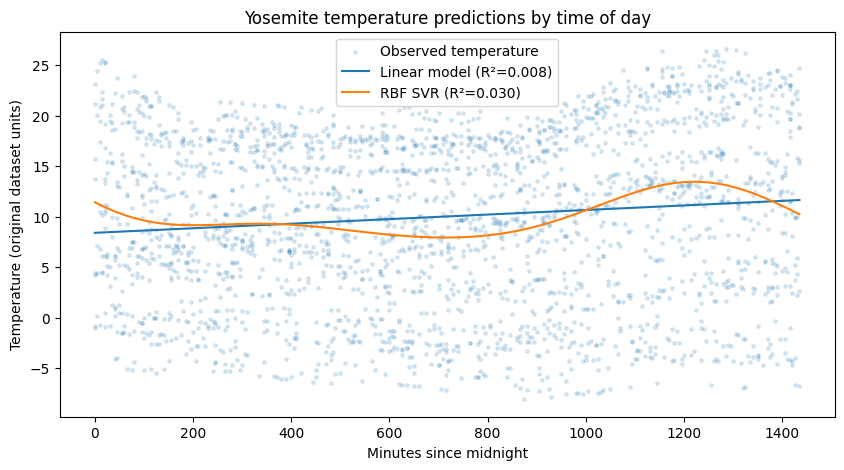

In [20]:
import matplotlib.pyplot as plt

# Sorting observations by time for clearer prediction curves
order = np.argsort(X_test_reg["minutes"].to_numpy())
minutes_sorted = X_test_reg["minutes"].to_numpy()[order]

# Plotting observed temperatures and model predictions
plt.figure(figsize=(10, 5))

plt.scatter(X_test_reg["minutes"], y_test_reg, s=6, alpha=0.15, label="Observed temperature")
plt.plot(minutes_sorted, linear_predictions[order], label=f"Linear model (R²={linear_r2:.3f})")
plt.plot(minutes_sorted, svr_predictions[order], label=f"RBF SVR (R²={svr_r2:.3f})")

plt.xlabel("Minutes since midnight")
plt.ylabel("Temperature (original dataset units)")
plt.title("Yosemite temperature predictions by time of day")
plt.legend()
plt.show()


### Interpretation — Linear Regression vs. RBF SVR

I compared linear regression and RBF support vector regression to determine whether a nonlinear model could better predict Yosemite temperature from time of day.

The linear regression model assumes a straight relationship between time and temperature. In contrast, SVR with an RBF kernel can capture curved patterns.

I compare the R² values calculated on the same test observations. A higher R² means that the model provides better predictions under this evaluation.

However, time of day alone may not explain all temperature variation. Seasonal differences, daily weather conditions, and other environmental factors can influence temperature at the same time of day.

The updated results should be interpreted using the corrected dataset rather than the earlier NOAA results.



# Session 13 — Final Reflection

In this session, I explored how support vector classifiers use different kernels to learn decision boundaries.

For the banknote dataset, the RBF kernel achieved the highest accuracy in my original experiment. This showed that a flexible nonlinear boundary could classify the test observations effectively.

For the Yosemite classification task, I compared three kernels using temperature as the only input. I also calculated a baseline to understand whether the models improved on a simple prediction strategy.

Finally, I compared linear regression with RBF support vector regression. This allowed me to examine whether a nonlinear model better represented the relationship between time of day and temperature.

My main takeaway is that kernels make support vector models more flexible; however, a more complex model is not necessarily better. The choice of features and the model's performance on unseen data are equally important.
